# Notebook 1: Reproducing TD3+BC (Fujimoto & Gu, NeurIPS 2021)

Assignment 2, Section 3. Two parts:

1. **Primary results.** TD3+BC on a subset of the paper's D4RL **v0** tasks, compared with Table 2.
2. **Ablation.** The paper's Figure 5 (no state normalization) and Figure 6 (alpha = 1) on Hopper-medium, 2 seeds.

Protocol, from Section 6 and Appendix B of the paper: 1,000,000 gradient steps, 10 evaluation episodes every 5,000 steps.
The score of a run is the mean of its **final 10 evaluations**. The paper averages that over 5 seeds. We use 2, which the assignment allows.

Code. The authors' `TD3_BC.py`, `utils.py` and `main.eval_policy` are used unchanged. Our additions are:

- `d4rl_compat.py`: loads the original D4RL hdf5 files. The paper's gym 0.17, mujoco-py 1.50 and `d4rl` no longer install.
- `train.py`: same training loop as `main.py`, plus checkpoints so a Colab disconnect resumes instead of restarting.

Known difference from the paper: evaluation runs in gymnasium's MuJoCo `-v4` environments (MuJoCo 3) instead of MuJoCo 1.50.

Free Colab T4: `JOBS = 2`. Re-running a training cell is safe. Finished runs are skipped and interrupted runs resume.


## 0. Setup

In [2]:
import os, sys, subprocess, importlib.util

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    # Edit this path to the package root on your Drive (folder that contains authors_code/ and our_code_tinkered/).
    os.chdir("/content/drive/MyDrive/8221/ass2/2026S2_COMP8221_Assignment2_49139568_60801131_Niloy_Zain")
    os.environ.setdefault("D4RL_DATASET_DIR", "/content/d4rl_datasets")

# Local or Colab: resolve package root and put both code folders on sys.path.
_HERE = os.getcwd()
for _cand in (_HERE, os.path.dirname(_HERE)):
    if os.path.isdir(os.path.join(_cand, "authors_code")) and os.path.isdir(os.path.join(_cand, "our_code_tinkered")):
        ROOT = _cand
        break
else:
    raise FileNotFoundError("Could not find package root containing authors_code/ and our_code_tinkered/")
os.chdir(ROOT)
sys.path[:0] = [os.path.join(ROOT, "authors_code"), os.path.join(ROOT, "our_code_tinkered")]

for module, package in [("torch", "torch"), ("h5py", "h5py"), ("mujoco", "gymnasium[mujoco]>=1.0"),
                        ("pandas", "pandas"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

import warnings
warnings.filterwarnings("ignore", message=".*is out of date.*")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import train
from d4rl_compat import _self_check
_self_check()
os.makedirs("figures", exist_ok=True)

SMOKE = os.environ.get("A2_SMOKE") == "1"  # tiny runs that only check every cell executes
print("folder:", os.getcwd())
print("device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU", "| CPU cores:", os.cpu_count())


Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/gymnasium/envs/registration.py:513: DeprecationWarning: WARN: The environment Hopper-v4 is out of date. You should consider upgrading to version `v5`.
  logger.deprecation(


d4rl_compat self-check passed
folder: /content/drive/.shortcut-targets-by-id/1clDN3u9kraqqJdiLoTcfd03o928tcEdW/8221/ass2/TD3_BC
device: Tesla T4 | CPU cores: 2


## 1. What to run

Edit this cell to change the scope. The defaults are the assignment-sized subset.

In [3]:
SEEDS = [0, 1]
MAIN_TASKS = [f"{env}-{data}-v0" for env in ("halfcheetah", "hopper", "walker2d") for data in ("medium", "medium-replay")]
ABLATION_TASKS = ["hopper-medium-v0"]
ABLATIONS = {  # paper Figure 6 (alpha) and Figure 5 (state normalization)
    "alpha = 1 (more BC)": ["--alpha", 1],
    "no state normalization": ["--normalize", "False"],
}
EVAL_FREQ = 5000  # paper; 25000 gives the same final-10 score with fewer learning-curve points
COMMON = ["--algo", "td3bc", "--eval_freq", EVAL_FREQ]
JOBS = 2  # free Colab T4: 2 runs at a time

if SMOKE:
    SEEDS, MAIN_TASKS, ABLATION_TASKS = [0], ["hopper-medium-replay-v0"], ["hopper-medium-replay-v0"]
    ABLATIONS = {"alpha = 1 (more BC)": ["--alpha", 1]}
    COMMON += ["--max_timesteps", 1200, "--eval_freq", 400, "--eval_episodes", 2, "--ckpt_freq", 400]
    JOBS = 2

assert set(ABLATION_TASKS) <= set(MAIN_TASKS), "ablations are compared against the full algorithm's runs"
main_runs = {(t, s): [*COMMON, "--env", t, "--seed", s] for t in MAIN_TASKS for s in SEEDS}
ablation_runs = {(name, t, s): [*COMMON, "--env", t, "--seed", s, *extra]
                 for name, extra in ABLATIONS.items() for t in ABLATION_TASKS for s in SEEDS}
print(f"{len(main_runs)} main runs + {len(ablation_runs)} ablation runs")


12 main runs + 4 ablation runs


## 2. How long will it take on this machine?

Optional. Skip this cell on free Colab if you are short on time. It does not start the Walker runs.
It times 1,000 training steps and scales up. Evaluation adds roughly 10 to 25%.


In [ ]:
# optional: estimates hours; skip it on free Colab if short on time
ms = train.benchmark(["--algo", "td3bc", "--env", "hopper-medium-replay-v0"],
                     steps=30 if SMOKE else 1000, warmup=10 if SMOKE else 100)
hours = ms * 1e6 / 3.6e6
n = len(main_runs) + len(ablation_runs)
print(f"{ms:.2f} ms per training step alone -> {hours:.2f} h per 1M-step run, before evaluation")
print(f"{n} runs, {JOBS} at a time -> about {n * hours / JOBS:.1f} h wall clock")


## 3. Primary results: run TD3+BC

This cell blocks until every run finishes. Stopping it stops the runs, and running it again resumes them.

## Live progress

The next cell redraws every 10 seconds. `running` plus a step number means that job is training. `failed` means it stopped. Stopping the cell stops the jobs; running it again continues from the checkpoint.


In [4]:
train.live(list(main_runs.values()), jobs=JOBS)

05:37:21
done      td3bc_halfcheetah-medium-v0_0
done      td3bc_halfcheetah-medium-v0_1
done      td3bc_halfcheetah-medium-replay-v0_0
done      td3bc_halfcheetah-medium-replay-v0_1
done      td3bc_hopper-medium-v0_0
done      td3bc_hopper-medium-v0_1
done      td3bc_hopper-medium-replay-v0_0
done      td3bc_hopper-medium-replay-v0_1
done      td3bc_walker2d-medium-v0_0
done      td3bc_walker2d-medium-v0_1
done      td3bc_walker2d-medium-replay-v0_0
done      td3bc_walker2d-medium-replay-v0_1


Progress, from a second cell or after a restart:

In [5]:
# Latest line of each training log: current step, score and speed of every run
import glob
for path in sorted(glob.glob("logs/*.log")):
    lines = [l for l in open(path) if "steps/s" in l or "done" in l or "Error" in l]
    print(lines[-1].strip() if lines else f"{os.path.basename(path)}: starting")


td3bc_halfcheetah-medium-replay-v0_0: done, final-10 mean 43.2
td3bc_halfcheetah-medium-replay-v0_1: done, final-10 mean 43.2
td3bc_halfcheetah-medium-v0_0: done, final-10 mean 41.3
td3bc_halfcheetah-medium-v0_1: done, final-10 mean 42.0
td3bc_hopper-medium-replay-v0_0: done, final-10 mean 27.8
td3bc_hopper-medium-replay-v0_1: done, final-10 mean 28.8
td3bc_hopper-medium-v0_0: done, final-10 mean 96.4
td3bc_hopper-medium-v0_0_alpha1.0: done, final-10 mean 29.8
td3bc_hopper-medium-v0_0_normalizeFalse: step 585000  score 30.3  125 steps/s
td3bc_hopper-medium-v0_1: done, final-10 mean 75.0
td3bc_hopper-medium-v0_1_alpha1.0: done, final-10 mean 29.8
td3bc_hopper-medium-v0_1_normalizeFalse: step 580000  score 30.9  125 steps/s
td3bc_walker2d-medium-replay-v0_0: done, final-10 mean 24.1
td3bc_walker2d-medium-replay-v0_1: done, final-10 mean 42.5
td3bc_walker2d-medium-v0_0: done, final-10 mean 77.6
td3bc_walker2d-medium-v0_1: done, final-10 mean 76.3


## 4. Ablation runs

In [6]:
train.live(list(ablation_runs.values()), jobs=JOBS)

06:40:08
done      td3bc_hopper-medium-v0_0_alpha1.0
done      td3bc_hopper-medium-v0_1_alpha1.0
done      td3bc_hopper-medium-v0_0_normalizeFalse
done      td3bc_hopper-medium-v0_1_normalizeFalse


## 5. Results compared with the paper

In [7]:
PAPER = {  # TD3+BC, Table 2 of Fujimoto & Gu (2021): final 10 evaluations, mean ± std over 5 seeds, D4RL v0
    "halfcheetah-random-v0": (10.2, 1.3), "hopper-random-v0": (11.0, 0.1), "walker2d-random-v0": (1.4, 1.6),
    "halfcheetah-medium-v0": (42.8, 0.3), "hopper-medium-v0": (99.5, 1.0), "walker2d-medium-v0": (79.7, 1.8),
    "halfcheetah-medium-replay-v0": (43.3, 0.5), "hopper-medium-replay-v0": (31.4, 3.0),
    "walker2d-medium-replay-v0": (25.2, 5.1),
    "halfcheetah-medium-expert-v0": (97.9, 4.4), "hopper-medium-expert-v0": (112.2, 0.2),
    "walker2d-medium-expert-v0": (101.1, 9.3),
    "halfcheetah-expert-v0": (105.7, 1.9), "hopper-expert-v0": (112.2, 0.2), "walker2d-expert-v0": (105.7, 2.7),
}


def finals(runs, keys):
    """Final-10 scores of the finished runs among `keys` (unfinished runs are skipped)."""
    out = [train.result(runs[k]) for k in keys]
    return [float(r["final_score"]) for r in out if r is not None]


def curve(rs, key="scores"):
    """Evaluation steps shared by all runs in `rs`, and each run's `key` values at those steps."""
    steps = rs[0]["steps"]
    for r in rs[1:]:
        steps = np.intersect1d(steps, r["steps"])
    return steps, np.array([r[key][np.isin(r["steps"], steps)] for r in rs])


def grid(n, width=4.3, height=3.4):
    cols = min(3, n)
    rows = -(-n // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(width * cols, height * rows), squeeze=False)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    return fig, axes.flat


In [8]:
rows = []
for t in MAIN_TASKS:
    ours = finals(main_runs, [(t, s) for s in SEEDS])
    rows.append({
        "task": t, "seeds done": len(ours),
        "ours mean": np.mean(ours) if ours else np.nan, "ours std": np.std(ours) if ours else np.nan,
        "paper mean": PAPER[t][0], "paper std": PAPER[t][1],
    })
table = pd.DataFrame(rows).set_index("task")
table["ours - paper"] = table["ours mean"] - table["paper mean"]
table.round(1).to_csv("figures/repro_table.csv")
table.round(1)

,seeds done,ours mean,ours std,paper mean,paper std,ours - paper
task,,,,,,
halfcheetah-medium-v0,2,41.7,0.3,42.8,0.3,-1.1
halfcheetah-medium-replay-v0,2,43.2,0.0,43.3,0.5,-0.1
hopper-medium-v0,2,85.7,10.7,99.5,1.0,-13.8
hopper-medium-replay-v0,2,28.3,0.5,31.4,3.0,-3.1
walker2d-medium-v0,2,76.9,0.6,79.7,1.8,-2.8
walker2d-medium-replay-v0,2,33.3,9.2,25.2,5.1,8.1


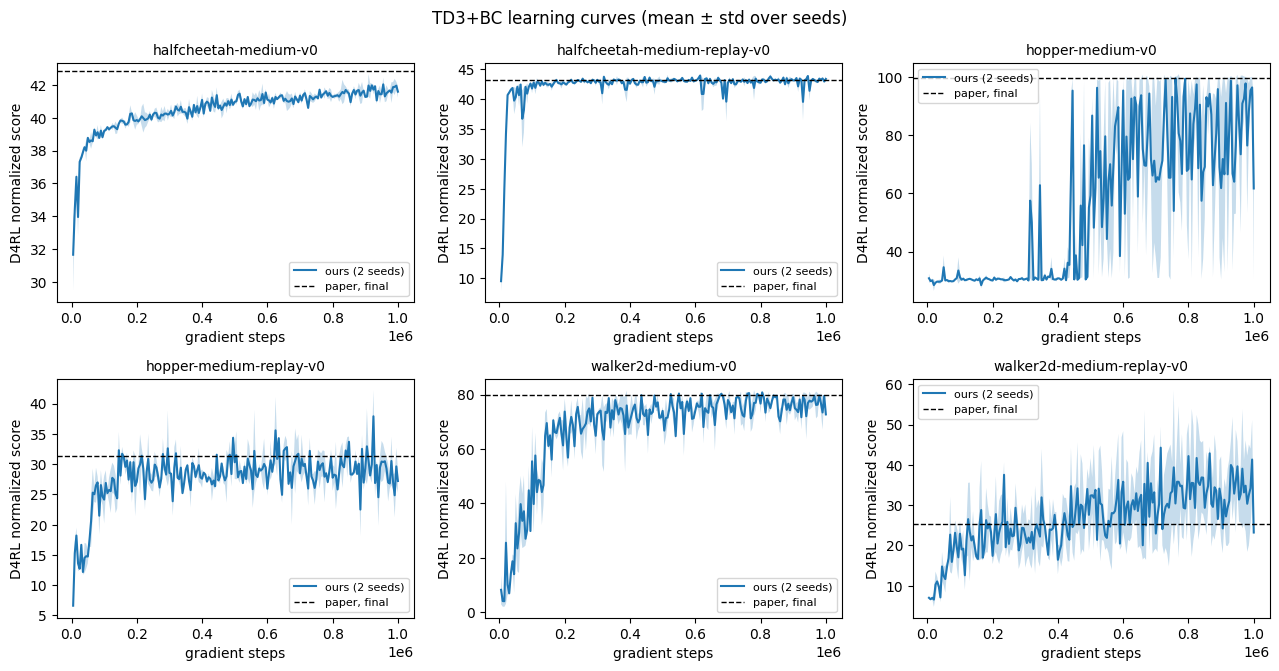

In [9]:
fig, axes = grid(len(MAIN_TASKS))
for ax, t in zip(axes, MAIN_TASKS):
    runs = [r for r in (train.result(main_runs[(t, s)]) for s in SEEDS) if r is not None]
    if runs:
        steps, y = curve(runs)
        ax.plot(steps, y.mean(0), label=f"ours ({len(runs)} seeds)")
        ax.fill_between(steps, y.mean(0) - y.std(0), y.mean(0) + y.std(0), alpha=0.25)
    ax.axhline(PAPER[t][0], ls="--", c="k", lw=1, label="paper, final")
    ax.set_title(t, fontsize=10)
    ax.set_xlabel("gradient steps")
    ax.set_ylabel("D4RL normalized score")
    ax.legend(fontsize=8)
fig.suptitle("TD3+BC learning curves (mean ± std over seeds)")
fig.tight_layout()
fig.savefig("figures/repro_curves.png", dpi=150)

### Ablation, shown as percent difference from the full algorithm (as in the paper's Figures 5 and 6)

Negative means removing or changing that part hurt.

,ablation,task,full,ablated,% difference
0,alpha = 1 (more BC),hopper-medium-v0,85.7,29.8,-65.2
1,no state normalization,hopper-medium-v0,85.7,34.9,-59.2


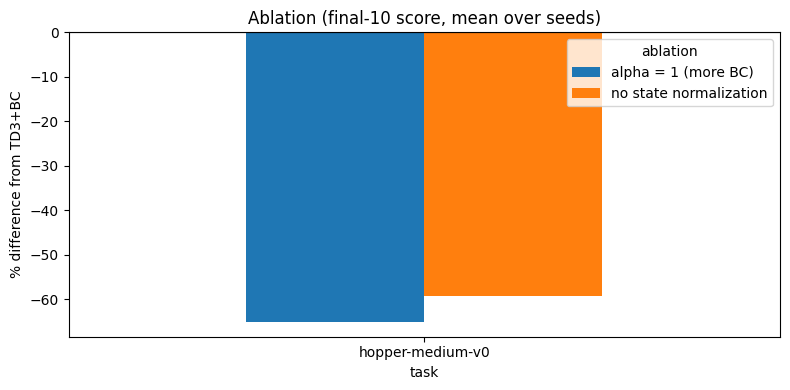

In [10]:
rows = []
for name in ABLATIONS:
    for t in ABLATION_TASKS:
        full = finals(main_runs, [(t, s) for s in SEEDS])
        ablated = finals(ablation_runs, [(name, t, s) for s in SEEDS])
        if full and ablated:
            rows.append({"ablation": name, "task": t, "full": np.mean(full), "ablated": np.mean(ablated),
                         "% difference": 100 * (np.mean(ablated) - np.mean(full)) / abs(np.mean(full))})
ablation_table = pd.DataFrame(rows)
ablation_table.round(1).to_csv("figures/repro_ablation.csv", index=False)

if rows:
    pivot = ablation_table.pivot(index="task", columns="ablation", values="% difference")
    ax = pivot.plot.bar(figsize=(8, 4), rot=0)
    ax.axhline(0, c="k", lw=0.8)
    ax.set_ylabel("% difference from TD3+BC")
    ax.set_title("Ablation (final-10 score, mean over seeds)")
    plt.tight_layout()
    plt.savefig("figures/repro_ablation.png", dpi=150)
ablation_table.round(1)